# SVM Breast Cancer Image Classification

In [1]:
# Chạy local: mở notebook từ thư mục Buoi_4 hoặc thư mục con.
from pathlib import Path  # Dùng đường dẫn đa nền tảng
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]  # Tìm thư mục dự án từ vị trí hiện tại
             if (p / 'Data' / 'dicom_info.csv').is_file()), None)  # Chọn thư mục có dữ liệu
if ROOT is None:  # Kiểm tra đã tìm thấy dự án
    raise FileNotFoundError('Không tìm thấy Data/dicom_info.csv. Mở Jupyter từ thư mục Buoi_4.')  # Báo lỗi khi thiếu thư mục dữ liệu
DATA_DIR = ROOT / 'Data'  # Đặt thư mục dữ liệu
MODEL_DIR = ROOT / 'models'  # Đặt thư mục lưu mô hình
MODEL_DIR.mkdir(exist_ok=True)  # Tạo thư mục nếu chưa có
# True: kiểm tra nhanh trên 80 dòng train và 40 dòng test. False: dùng toàn bộ dữ liệu.
QUICK_RUN = False  # Bật hoặc tắt chạy nhanh
# Bật khi muốn tìm tham số; chậm hơn huấn luyện SVM mặc định.
RUN_GRID_SEARCH = False  # Bật hoặc tắt tìm tham số
print('Thư mục dự án:', ROOT)  # In thư mục đang sử dụng


Thư mục dự án: /Volumes/Workspace /Cybersoft/ML07/Buoi4_Code


In [3]:
!python -m pip install -r requirements.txt

1. Import các thư viện code

In [6]:
import matplotlib.pyplot as plt # Dùng hàm vẽ biểu đồ
import seaborn as sns # Dùng biểu đồ thống kê 
import numpy as np
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler # Dùng bộ chuẩn hóa đặc trưng
import matplotlib.image as mpimg
from skimage.feature import hog # Trích xuất đặc trưng HOG
from skimage.transform import resize # Thay đổi kích thước ảnh
import os 

In [7]:
# Đọc file meta.csv -> mô tả các series ảnh của Data
df_meta = pd.read_csv(DATA_DIR / 'meta.csv')
df_meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6775 entries, 0 to 6774
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   SeriesInstanceUID  6775 non-null   object
 1   StudyInstanceUID   6775 non-null   object
 2   Modality           6775 non-null   object
 3   SeriesDescription  6775 non-null   object
 4   BodyPartExamined   6775 non-null   object
 5   SeriesNumber       6775 non-null   int64 
 6   Collection         6775 non-null   object
 7   Visibility         6775 non-null   int64 
 8   ImageCount         6775 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 476.5+ KB


In [9]:
 # Đọc file dicom_info.csv
df_dicom = pd.read_csv(DATA_DIR / 'dicom_info.csv')
df_meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6775 entries, 0 to 6774
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   SeriesInstanceUID  6775 non-null   object
 1   StudyInstanceUID   6775 non-null   object
 2   Modality           6775 non-null   object
 3   SeriesDescription  6775 non-null   object
 4   BodyPartExamined   6775 non-null   object
 5   SeriesNumber       6775 non-null   int64 
 6   Collection         6775 non-null   object
 7   Visibility         6775 non-null   int64 
 8   ImageCount         6775 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 476.5+ KB


In [10]:
# Liệt kê các loại ảnh 
df_dicom.SeriesDescription.unique()

array(['cropped images', 'full mammogram images', nan, 'ROI mask images'],
      dtype=object)

In [ ]:
# Liệt kê các ảnh Crop
cropped_images = df_dicom[df_dicom.SeriesDescription=='cropped images'].image_path
cropped_images.head(5)

0     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...
3     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...
6     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...
7     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...
10    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833...
Name: image_path, dtype: object

In [12]:
# Lọc các đường dẫn ảnh ROI
roi_img = df_dicom[df_dicom.SeriesDescription=='ROI mask images'].image_path
roi_img.head(5)

5     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...
8     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...
9     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833...
14    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.236373...
20    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.357008...
Name: image_path, dtype: object

In [17]:
#full mammogram images
full_mammo = df_dicom[df_dicom.SeriesDescription=='full mammogram images'].image_path  # Lọc đường dẫn ảnh toàn cảnh
full_mammo.head(5)  # Xem 5 đường dẫn đầu


1     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...
2     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...
11    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396...
12    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.749566...
15    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.987658...
Name: image_path, dtype: object

In [15]:
# Đường dẫn thư mục ảnh JPEG
imdir = str(DATA_DIR / 'jpeg')
print(imdir)

/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/Data/jpeg


In [18]:
# Chỉ thay tiền tố của dataset bằng thư mục ảnh local.
def local_image_path(path):  # Định nghĩa hàm đổi đường dẫn
    parts = Path(path).parts  # Tách các phần đường dẫn
    return str(DATA_DIR / 'jpeg' / parts[-2] / parts[-1])  # Ghép UID và tên ảnh vào thư mục local
cropped_images = cropped_images.map(local_image_path)  # Đổi đường dẫn ảnh crop
full_mammo = full_mammo.map(local_image_path)  # Đổi đường dẫn ảnh toàn cảnh
roi_img = roi_img.map(local_image_path)  # Đổi đường dẫn ảnh mặt nạ
print('Ảnh crop mẫu:', cropped_images.iloc[0])  # In đường dẫn ảnh mẫu


Ảnh crop mẫu: /Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/Data/jpeg/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.jpg


In [19]:
# Tạo bảng tra cứu UID -> đường dẫn; crop và ảnh toàn cảnh có UID riêng 
full_mammo_dict = dict()
cropped_images_dict = dict()
roi_img_dict = dict()

for dicom in full_mammo:
    key = dicom.split("/")[-2]
    full_mammo_dict[key] = dicom

for dicom in cropped_images:
    key = dicom.split("/")[-2]
    cropped_images_dict[key] = dicom

for dicom in roi_img:
    key = dicom.split("/")[-2]
    roi_img_dict[key] = dicom

print('Full mammo dict key example: ')
print(next(iter(full_mammo_dict.items())))
print('\nROI mask images dict key example: ')
print(next(iter(roi_img_dict.items())))

Full mammo dict key example: 
('1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849', '/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/Data/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg')

ROI mask images dict key example: 
('1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138', '/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/Data/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.jpg')


In [20]:
mass_train = pd.read_csv(DATA_DIR / 'mass_case_description_train_set.csv')  # Đọc dữ liệu huấn luyện
mass_test = pd.read_csv(DATA_DIR / 'mass_case_description_test_set.csv')  # Đọc dữ liệu kiểm tra
mass_train.head()  # Xem các dòng train đầu


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....


In [21]:
# CSV chứa đường dẫn DICOM; dùng UID thư mục để tìm đúng ảnh JPEG.
# Truy cập theo tên cột để không phụ thuộc thứ tự cột trong CSV.
def fix_image_path(data):  # Định nghĩa hàm sửa đường dẫn
    for column, lookup in [('image file path', full_mammo_dict),  # Chọn cột ảnh toàn cảnh và bảng tra
                           ('cropped image file path', cropped_images_dict)]:  # Chọn cột ảnh crop và bảng tra
        paths = []  # Tạo danh sách đường dẫn mới
        for value in data[column]:  # Duyệt từng đường dẫn cũ
            uid = str(value).strip().split('/')[-2]  # Lấy UID và bỏ khoảng trắng
            if uid not in lookup:  # Kiểm tra UID trong bảng tra
                raise ValueError(f'Không tìm thấy UID {uid} cho {column}')  # Báo lỗi nếu thiếu UID
            path = lookup[uid]  # Lấy đường dẫn JPEG
            if not Path(path).is_file():  # Kiểm tra file ảnh tồn tại
                raise FileNotFoundError(f'Thiếu ảnh: {path}')  # Báo lỗi nếu thiếu ảnh
            paths.append(path)  # Thêm đường dẫn hợp lệ
        data[column] = paths  # Cập nhật cột đường dẫn
fix_image_path(mass_train)  # Sửa đường dẫn tập train
fix_image_path(mass_test)  # Sửa đường dẫn tập test


In [22]:
# Liệt kê các nhãn bệnh lý 
mass_train.pathology.unique()

array(['MALIGNANT', 'BENIGN', 'BENIGN_WITHOUT_CALLBACK'], dtype=object)

In [23]:
# rename columns
mass_train = mass_train.rename(columns={'left or right breast': 'left_or_right_breast',  # Đổi tên cột bên ngực
                                           'image view': 'image_view',  # Đổi tên cột góc chụp
                                           'abnormality id': 'abnormality_id',  # Đổi tên cột mã bất thường
                                           'abnormality type': 'abnormality_type',  # Đổi tên cột loại bất thường
                                           'mass shape': 'mass_shape',  # Đổi tên cột hình dạng khối
                                           'mass margins': 'mass_margins',  # Đổi tên cột bờ khối
                                           'image file path': 'image_file_path',  # Đổi tên cột ảnh toàn cảnh
                                           'cropped image file path': 'cropped_image_file_path',  # Đổi tên cột ảnh crop
                                           'ROI mask file path': 'ROI_mask_file_path'})  # Đổi tên cột mặt nạ ROI

mass_train.head(5)  # Xem 5 dòng sau đổi tên


,patient_id,breast_density,left_or_right_breast,image_view,abnormality_id,abnormality_type,mass_shape,mass_margins,assessment,pathology,subtlety,image_file_path,cropped_image_file_path,ROI_mask_file_path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....


In [25]:
mass_train['mass_shape'] = mass_train['mass_shape'].bfill()
mass_train['mass_margins'] = mass_train['mass_margins'].bfill()

mass_train.isnull().sum()

patient_id                 0
breast_density             0
left_or_right_breast       0
image_view                 0
abnormality_id             0
abnormality_type           0
mass_shape                 0
mass_margins               0
assessment                 0
pathology                  0
subtlety                   0
image_file_path            0
cropped_image_file_path    0
ROI_mask_file_path         0
dtype: int64

In [27]:
mass_test = mass_test.rename(columns={'left or right breast': 'left_or_right_breast',  # Đổi tên cột bên ngực
                                           'image view': 'image_view',  # Đổi tên cột góc chụp
                                           'abnormality id': 'abnormality_id',  # Đổi tên cột mã bất thường
                                           'abnormality type': 'abnormality_type',  # Đổi tên cột loại bất thường
                                           'mass shape': 'mass_shape',  # Đổi tên cột hình dạng khối
                                           'mass margins': 'mass_margins',  # Đổi tên cột bờ khối
                                           'image file path': 'image_file_path',  # Đổi tên cột ảnh toàn cảnh
                                           'cropped image file path': 'cropped_image_file_path',  # Đổi tên cột ảnh crop
                                           'ROI mask file path': 'ROI_mask_file_path'})  # Đổi tên cột mặt nạ ROI

mass_test.head(5)


,patient_id,breast_density,left_or_right_breast,image_view,abnormality_id,abnormality_type,mass_shape,mass_margins,assessment,pathology,subtlety,image_file_path,cropped_image_file_path,ROI_mask_file_path
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,4,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,4,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Test_P_00017_LEFT_MLO_1/1.3.6.1.4.1.9590....
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,2,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,/Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/...,Mass-Test_P_00032_RIGHT_CC_1/1.3.6.1.4.1.9590....


In [28]:
# fill in missing values using the backwards fill method
mass_test['mass_margins'] = mass_test['mass_margins'].bfill()  # Điền bờ khối thiếu từ dòng sau

#check null values
mass_test.isnull().sum()  # Đếm giá trị thiếu theo cột


patient_id                 0
breast_density             0
left_or_right_breast       0
image_view                 0
abnormality_id             0
abnormality_type           0
mass_shape                 0
mass_margins               0
assessment                 0
pathology                  0
subtlety                   0
image_file_path            0
cropped_image_file_path    0
ROI_mask_file_path         0
dtype: int64

2. Visualize

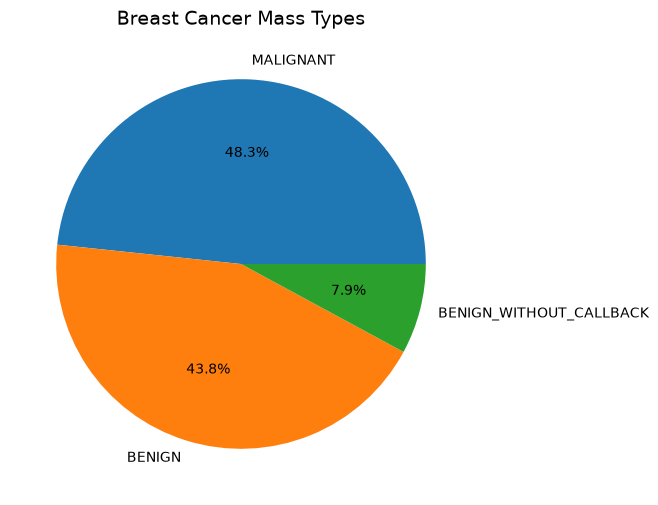

In [29]:
# Quan sát mức cân bằng nhãn trước khi huấn luyện.
# pathology distributions
value = mass_train['pathology'].value_counts()  # Đếm số dòng của từng nhãn
plt.figure(figsize=(8,6))  # Tạo khung biểu đồ

plt.pie(value, labels=value.index, autopct='%1.1f%%')  # Vẽ tỷ lệ nhãn theo phần trăm
plt.title('Breast Cancer Mass Types', fontsize=14)  # Đặt tiêu đề biểu đồ
# plt.savefig('/kaggle/working/pathology_distributions_red.png')
plt.show()  # Hiển thị biểu đồ


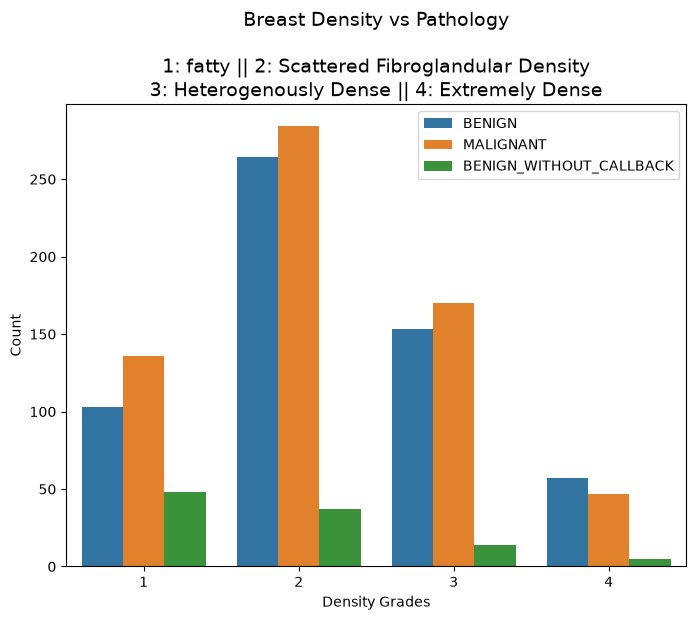

In [30]:
# breast density against pathology
plt.figure(figsize=(8,6))  # Tạo khung biểu đồ

sns.countplot(mass_train, x='breast_density', hue='pathology')  # Đếm mật độ vú theo bệnh lý
plt.title('Breast Density vs Pathology\n\n1: fatty || 2: Scattered Fibroglandular Density\n3: Heterogenously Dense || 4: Extremely Dense',  # Đặt tiêu đề và giải thích mật độ
          fontsize=14)  # Đặt cỡ chữ tiêu đề
plt.xlabel('Density Grades')  # Đặt tên trục mật độ
plt.ylabel('Count')  # Đặt tên trục số lượng
plt.legend()  # Hiện chú giải nhãn
# plt.savefig('/kaggle/working/density_pathology_red.png')
plt.show()  # Hiển thị biểu đồ


Full Mammograms:



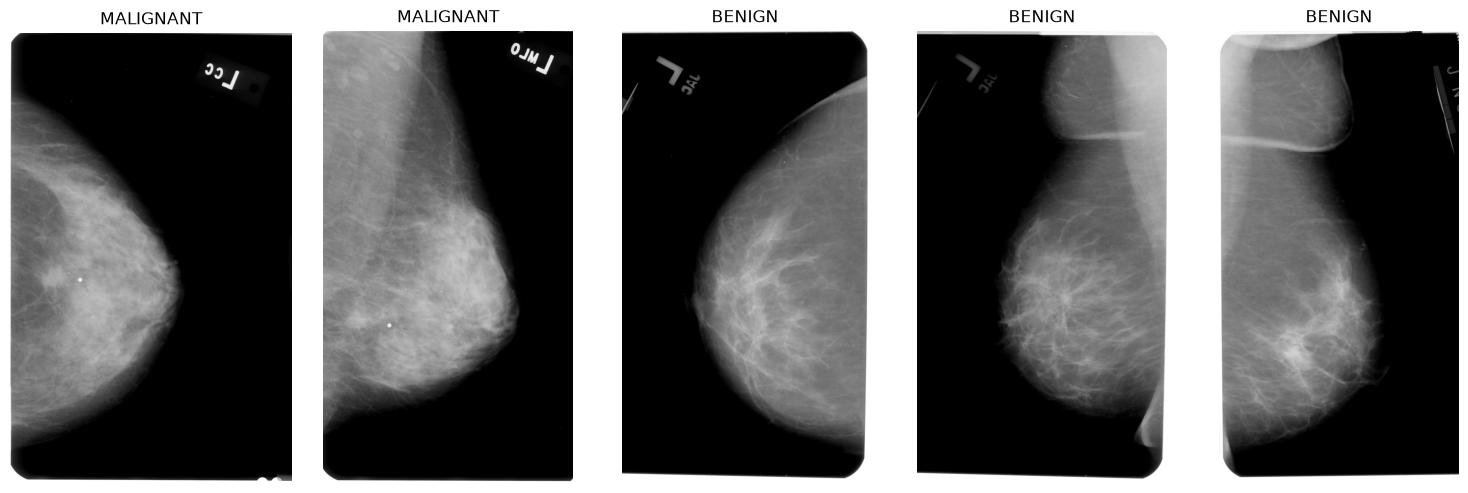

Cropped Mammograms:



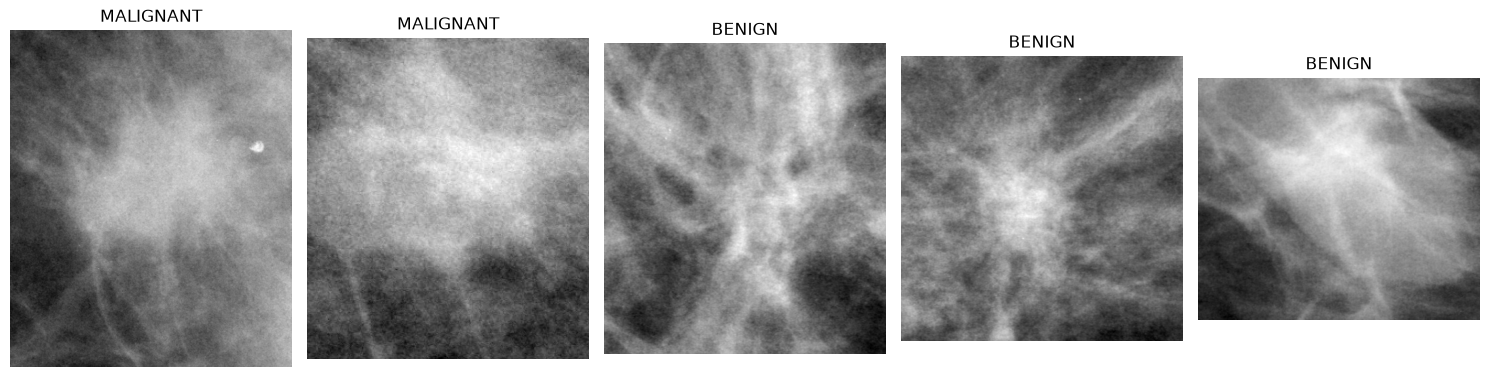

In [31]:
# Hiển thị ảnh toàn cảnh và vùng crop để kiểm tra ánh xạ bằng mắt.
# Display some images
import matplotlib.image as mpimg  # Dùng hàm đọc ảnh

# create function to display images
def display_images(column, number):  # Định nghĩa hàm hiển thị ảnh
    # create figure and axes
    number_to_visualize = number  # Lấy số ảnh cần hiển thị
    rows = 1  # Đặt số hàng biểu đồ
    cols = number_to_visualize  # Đặt số cột theo số ảnh
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5))  # Tạo các ô hiển thị

    # Loop through rows and display images
    for index, row in mass_train.head(number_to_visualize).iterrows():  # Duyệt các dòng dữ liệu đầu
        image_path = row[column]  # Lấy đường dẫn ở cột chọn
        image = mpimg.imread(image_path)  # Đọc ảnh từ đường dẫn
        ax = axes[index]  # Chọn ô vẽ tương ứng
        ax.imshow(image, cmap='gray')  # Vẽ ảnh thang xám
        ax.set_title(f"{row['pathology']}")  # Hiển thị nhãn bệnh lý
        ax.axis('off')  # Ẩn trục tọa độ
    plt.tight_layout()  # Căn khoảng cách giữa các ảnh
    plt.show()  # Hiển thị các ảnh

print('Full Mammograms:\n')  # In tiêu đề ảnh toàn cảnh
display_images('image_file_path', 5)  # Hiển thị 5 ảnh toàn cảnh
print('Cropped Mammograms:\n')  # In tiêu đề ảnh crop
display_images('cropped_image_file_path', 5)  # Hiển thị 5 ảnh crop


In [32]:
# Chuẩn hóa kích thước ảnh rồi mô tả cạnh/gradient bằng HOG.
# Báo lỗi ngay nếu ảnh hỏng: bỏ qua ảnh sẽ làm lệch đặc trưng và nhãn.
def extract_features(image_paths, target_size=(128, 128)):  # Định nghĩa hàm trích xuất đặc trưng
    features = []  # Tạo danh sách đặc trưng
    for path in image_paths:  # Duyệt đường dẫn từng ảnh
        img = mpimg.imread(path)  # Đọc ảnh đầu vào
        if img.ndim == 3:  # Kiểm tra ảnh nhiều kênh
            img = np.mean(img[..., :3], axis=2)  # Lấy trung bình RGB thành ảnh xám
        img_resized = resize(img, target_size, anti_aliasing=True)  # Đưa ảnh về kích thước cố định
        descriptor = hog(img_resized, pixels_per_cell=(16, 16),  # Tính HOG với ô 16×16 pixel
                         cells_per_block=(2, 2), feature_vector=True)  # Ghép khối 2×2 ô thành vector
        features.append(np.concatenate([descriptor, [img_resized.mean(), img_resized.std()]]))  # Ghép HOG với trung bình và độ lệch chuẩn
    if not features:  # Kiểm tra danh sách đặc trưng rỗng
        raise ValueError('Danh sách ảnh rỗng.')  # Báo lỗi khi không có ảnh
    return np.asarray(features)  # Trả về ma trận đặc trưng


In [33]:
# Dự đoán phải dùng cùng cách trích xuất HOG và scaler đã fit khi train.
# Function to test and display predictions for specific images
def test_and_display_images(model, scaler, image_paths, labels, number=5):  # Định nghĩa hàm minh họa dự đoán
    # Extract features for the selected images
    features = extract_features(image_paths[:number])  # Lấy đặc trưng các ảnh được chọn
    if len(features) == 0:  # Kiểm tra có đặc trưng hợp lệ
        print("No valid images to process.")  # Thông báo không có ảnh hợp lệ
        return  # Dừng hàm khi thiếu ảnh

    # Scale features
    features_scaled = scaler.transform(features)  # Chuẩn hóa bằng scaler đã fit

    # Predict
    predictions = model.predict(features_scaled)  # Dự đoán nhãn bằng SVM
    label_map = {0: 'Benign', 1: 'Malignant'}  # Đổi nhãn số sang tên

    # Display images with predictions
    fig, axes = plt.subplots(1, number, figsize=(15, 5))  # Tạo các ô hiển thị ảnh
    for idx, (path, pred, actual) in enumerate(zip(image_paths[:number], predictions, labels[:number])):  # Duyệt ảnh cùng dự đoán và nhãn thật
        img = mpimg.imread(path)  # Đọc ảnh để minh họa
        ax = axes[idx] if number > 1 else axes  # Chọn ô tương ứng từng ảnh
        ax.imshow(img, cmap='gray')  # Vẽ ảnh thang xám
        ax.set_title(f"Pred: {label_map[pred]}\nActual: {label_map[actual]}")  # Hiện nhãn dự đoán và nhãn thật
        ax.axis('off')  # Ẩn trục tọa độ
    plt.tight_layout()  # Căn khoảng cách giữa các ảnh
    # plt.savefig('/kaggle/working/test_image_predictions.png')
    plt.show()  # Hiển thị kết quả


Trích xuất HOG: 1318 train, 378 test...
Test accuracy: 0.6481
              precision    recall  f1-score   support

      Benign       0.72      0.70      0.71       231
   Malignant       0.55      0.56      0.56       147

    accuracy                           0.65       378
   macro avg       0.63      0.63      0.63       378
weighted avg       0.65      0.65      0.65       378



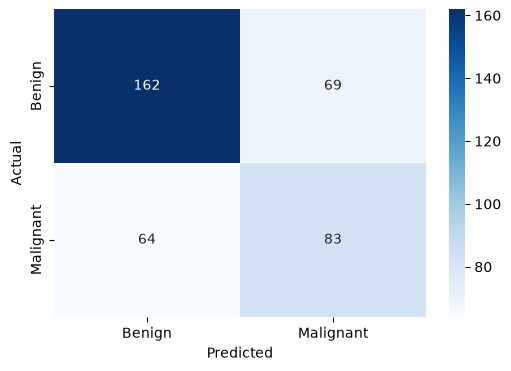

In [34]:
from sklearn.pipeline import Pipeline  # Dùng pipeline xử lý liên tiếp
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold  # Dùng tìm tham số và chia fold theo nhóm
from sklearn.metrics import accuracy_score  # Dùng thước đo độ chính xác

# Hai loại BENIGN đều được gộp về 0; MALIGNANT là 1.
label_mapping = {'BENIGN': 0, 'BENIGN_WITHOUT_CALLBACK': 0, 'MALIGNANT': 1}  # Ánh xạ bệnh lý thành nhãn số
for data in (mass_train, mass_test):  # Duyệt hai tập dữ liệu
    data['label'] = data['pathology'].map(label_mapping)  # Tạo cột nhãn từ bệnh lý
    if data['label'].isna().any():  # Kiểm tra nhãn chưa được ánh xạ
        raise ValueError('Dataset có pathology chưa được định nghĩa.')  # Báo lỗi nếu gặp bệnh lý lạ

# Giữ nguyên train/test gốc. Chạy nhanh lấy mẫu cố định để tái lập kết quả.
train_data = mass_train.sample(n=min(80, len(mass_train)), random_state=42) if QUICK_RUN else mass_train  # Lấy mẫu train khi chạy nhanh
test_data = mass_test.sample(n=min(40, len(mass_test)), random_state=42) if QUICK_RUN else mass_test  # Lấy mẫu test khi chạy nhanh
print(f'Trích xuất HOG: {len(train_data)} train, {len(test_data)} test...')  # In số dòng cần xử lý
X_train = extract_features(train_data['cropped_image_file_path'])  # Trích xuất đặc trưng train
X_test = extract_features(test_data['cropped_image_file_path'])  # Trích xuất đặc trưng test
y_train = train_data['label'].to_numpy(dtype=int)  # Lấy nhãn train dạng số nguyên
y_test = test_data['label'].to_numpy(dtype=int)  # Lấy nhãn test dạng số nguyên

# Pipeline fit scaler chỉ trên train (và riêng từng fold khi tìm tham số).
model = Pipeline([('scaler', StandardScaler()),  # Thêm bước chuẩn hóa vào pipeline
                  ('svm', SVC(kernel='rbf', C=1, gamma='scale', random_state=42))])  # Thêm SVM dùng kernel RBF
if RUN_GRID_SEARCH:  # Kiểm tra chế độ tìm tham số
    # Chia theo bệnh nhân để ảnh cùng bệnh nhân không lọt vào hai fold.
    cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)  # Tạo 3 fold phân tầng theo bệnh nhân
    grid_search = GridSearchCV(model, {'svm__C': [0.1, 1, 10],  # Thử các giá trị tham số C
                                      'svm__gamma': ['scale', 0.001]},  # Thử các giá trị gamma
                               cv=cv, scoring='accuracy', n_jobs=1)  # Chấm accuracy và chạy một luồng
    grid_search.fit(X_train, y_train, groups=train_data['patient_id'])  # Tìm tham số theo nhóm bệnh nhân
    model = grid_search.best_estimator_  # Lấy pipeline tốt nhất đã fit
    print('Tham số tốt nhất:', grid_search.best_params_)  # In bộ tham số tốt nhất
else:  # Chọn nhánh huấn luyện mặc định
    model.fit(X_train, y_train)  # Huấn luyện pipeline trên train
# Các cell minh họa bên dưới dùng đúng SVM và scaler đã fit.
scaler = model.named_steps['scaler']  # Lấy scaler đã huấn luyện
svm_model = model.named_steps['svm']  # Lấy SVM đã huấn luyện
y_pred = model.predict(X_test)  # Dự đoán nhãn tập test
print(f'Test accuracy: {accuracy_score(y_test, y_pred):.4f}')  # In độ chính xác trên test
print(classification_report(y_test, y_pred, labels=[0, 1],  # Tính báo cáo phân loại hai nhãn
                            target_names=['Benign', 'Malignant'], zero_division=0))  # Đặt tên nhãn và xử lý chia cho 0
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])  # Tính ma trận nhầm lẫn
plt.figure(figsize=(6, 4))  # Tạo khung biểu đồ
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',  # Vẽ số lượng dự đoán bằng màu
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])  # Đặt tên hai nhãn trên các trục
plt.xlabel('Predicted')  # Đặt tên trục dự đoán
plt.ylabel('Actual')  # Đặt tên trục thực tế
plt.show()  # Hiển thị ma trận nhầm lẫn


In [35]:
# Điểm train để đối chiếu với test và quan sát khả năng overfit.
print(classification_report(y_train, model.predict(X_train), labels=[0, 1],  # Đánh giá dự đoán trên tập train
                            target_names=['Benign', 'Malignant'], zero_division=0))  # Đặt tên nhãn và xử lý chia cho 0


              precision    recall  f1-score   support

      Benign       0.91      0.97      0.94       681
   Malignant       0.96      0.89      0.93       637

    accuracy                           0.93      1318
   macro avg       0.94      0.93      0.93      1318
weighted avg       0.94      0.93      0.93      1318



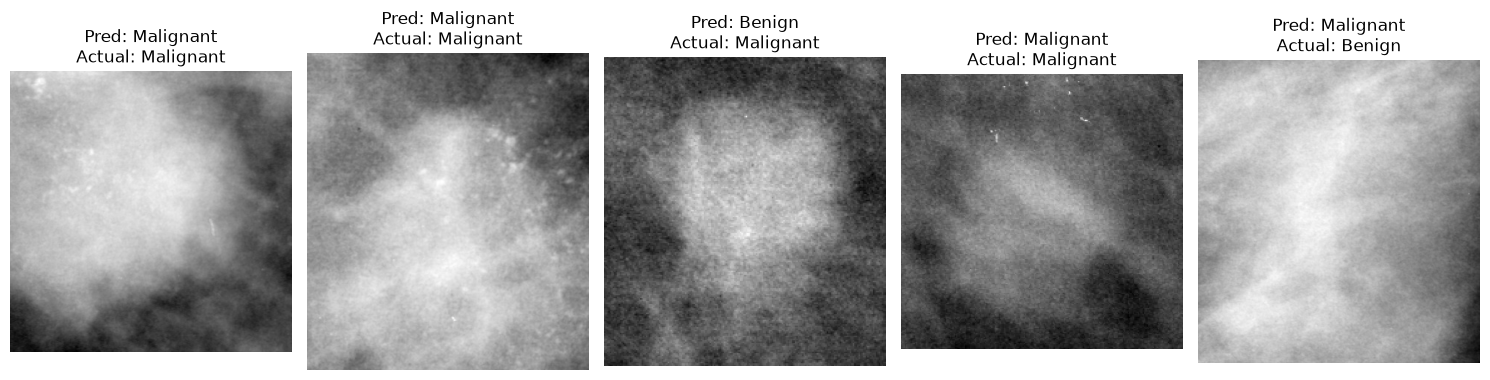

In [36]:
# Chuyển sang list để slicing theo vị trí, kể cả sau sample().
test_and_display_images(svm_model, scaler,  # Dùng SVM và scaler đã huấn luyện
                        test_data['cropped_image_file_path'].tolist(),  # Lấy danh sách đường dẫn ảnh test
                        test_data['label'].tolist(), number=5)  # Lấy nhãn thật và hiển thị 5 ảnh


In [37]:
import pickle  # Dùng thư viện lưu đối tượng Python
# Lưu cả pipeline để khi dùng lại không quên bước chuẩn hóa.
with (MODEL_DIR / 'svm_pipeline.pkl').open('wb') as f:  # Mở file lưu pipeline dạng nhị phân
    pickle.dump(model, f)  # Lưu pipeline đã huấn luyện
# Giữ hai file riêng cho mục đích học và so sánh với notebook ban đầu.
for filename, fitted_object in [('svm_model_pickle.pkl', svm_model),  # Chọn tên file và SVM cần lưu
                                 ('scaler_pickle.pkl', scaler)]:  # Chọn tên file và scaler cần lưu
    with (MODEL_DIR / filename).open('wb') as f:  # Mở file đích dạng nhị phân
        pickle.dump(fitted_object, f)  # Ghi đối tượng đã huấn luyện
print('Đã lưu mô hình tại:', MODEL_DIR)  # In thư mục lưu kết quả


Đã lưu mô hình tại: /Volumes/Workspace /Cybersoft/ML07/Buoi4_Code/models
